We need to put some results for the department seminar presentation slide. Professor said I should make DO-Nutrient diagram and also T-S diagram with colored dots to show the DO value.

In [2]:
# Imports
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as colors

In [3]:
# In [2]: Load and Prepare Data
# Load the pre-processed data
merged_gdf = pd.read_feather('../data/processed/merged_gdf.feather', use_threads=False)
merged_gdf = gpd.GeoDataFrame(merged_gdf, geometry=gpd.points_from_xy(merged_gdf.longitude, merged_gdf.latitude), crs='EPSG:4326')

# Filter summer bottom do data
summer_bottom_df = merged_gdf[
    (merged_gdf['season'] == 'Summer') &
    (merged_gdf['saisuipoin'] == 2)
].dropna(subset=['do_']).copy()

print(summer_bottom_df.head())

      uniqueid zettaicode locationna wancode prefectuei  watercode renban  \
4   0000001734   00002811      兵庫県11      03         28        301     11   
12  0000001742   00002823      兵庫県23      03         28        301     23   
19  0000001678   00000272       大阪府2      03         27        301      2   
27  0000001686   00000275       大阪府5      03         27        301      5   
35  0000001694   00002725      大阪府25      03         27        301     25   

    nendo  survey_ym  surveyyear  ...   doc  doc2  dataflag  scale  \
4    1981 1981-06-01        1981  ...  None   0.0         1     -1   
12   1981 1981-06-01        1981  ...  None   0.0         1     -1   
19   1981 1981-06-01        1981  ...  None   0.0         1     -1   
27   1981 1981-06-01        1981  ...  None   0.0         1     -1   
35   1981 1981-06-01        1981  ...  None   0.0         1     -1   

                      geometry  year   watermass_name   division  \
4     POINT (135.33056 34.695)  1981  Seto Inlan

In [4]:
print(summer_bottom_df['division'].unique())
print(summer_bottom_df.columns)

['Osaka Bay' 'Harima Nada' 'Iyo Nada' 'Suo Nada' 'Bisan Seto' 'Bingo Nada'
 'Bungo Channel' 'Hibiki Nada' 'Kii Channel' 'Aki Nada' 'Hiroshima Bay'
 'Hiuchi Nada']
Index(['uniqueid', 'zettaicode', 'locationna', 'wancode', 'prefectuei',
       'watercode', 'renban', 'nendo', 'survey_ym', 'surveyyear', 'surveymont',
       'surveyday', 'surveyhour', 'surveymini', 'saisuipoin', 'latitude',
       'longitude', 'weather', 'cloud', 'fuko', 'fusoku', 'temp', 'color',
       'saisuidept', 'depth', 'clearness', 'wtemp', 'ph', 'ph2', 'do_', 'do_2',
       'salt', 'salt2', 'cod', 'cod2', 'rcod', 'rcod2', 'nh4n', 'nh4n2',
       'no2n', 'no2n2', 'no3n', 'no3n2', 'tn', 'tn2', 'po4p', 'po4p2', 'tp',
       'tp2', 'chlorophyl', 'chloroph_1', 'feiochin', 'feiochin2', 'toc',
       'toc2', 'doc', 'doc2', 'dataflag', 'scale', 'geometry', 'year',
       'watermass_name', 'division', 'details', 'season'],
      dtype='object')


Valid rows for T-S plot: 5188
S range: 7.50 - 39.74 PSU
T range: 12.60 - 29.80 °C
DO range: 0.10 - 12.00 mg/L


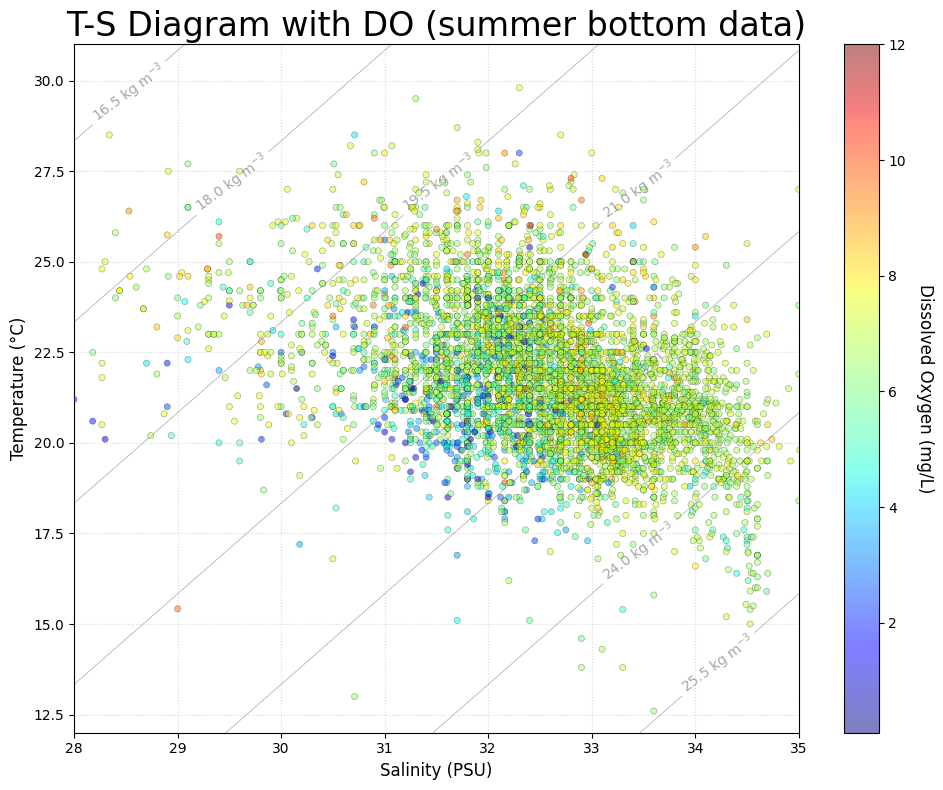

In [5]:
# --- STEP 1: Define the Density Calculation Function ---
# This linear approximation is standard for visualizing "Isopycnals" 
# within standard ranges (10-30°C, 25-35 PSU).
def calculate_density(T, S):
    return (0.75 * S) - (0.3 * T) + 4.0

# --- STEP 2: Prepare Data & Grid ---
# Safe numeric conversion (follow repo pattern: convert before aggregation)
S = pd.to_numeric(summer_bottom_df['salt'], errors='coerce').dropna()
T = pd.to_numeric(summer_bottom_df['wtemp'], errors='coerce').dropna()
DO = pd.to_numeric(summer_bottom_df['do_'], errors='coerce').dropna()

# Align indices after dropna (remove rows where any of S, T, DO is NaN)
valid_idx = S.index.intersection(T.index).intersection(DO.index)
S = S.loc[valid_idx]
T = T.loc[valid_idx]
DO = DO.loc[valid_idx]

if len(S) == 0:
    raise ValueError("No valid S, T, DO data after coercion. Check column names and data types.")

print(f"Valid rows for T-S plot: {len(S)}")
print(f"S range: {S.min():.2f} - {S.max():.2f} PSU")
print(f"T range: {T.min():.2f} - {T.max():.2f} °C")
print(f"DO range: {DO.min():.2f} - {DO.max():.2f} mg/L")

# Set manual limits for better visualization
s_min, s_max = 28.0, 35.0   # Salinity: Ignore the low outliers < 28
t_min, t_max = 12.0, 31.0   # Temperature: Focus on 12-31°C

# Create a background grid for the grey lines
s_grid = np.linspace(s_min, s_max, 100)
t_grid = np.linspace(t_min, t_max, 100)
S_grid, T_grid = np.meshgrid(s_grid, t_grid)
Sigma_grid = calculate_density(T_grid, S_grid)

# --- STEP 3: Create the Plot ---
plt.figure(figsize=(10, 8))

# A. Draw the Grey Isopycnals (Density Lines)
# We plot contours every 0.5 or 1.0 unit of density
contours = plt.contour(S_grid, T_grid, Sigma_grid, 
                       colors='grey', linestyles='-', linewidths=0.5, alpha=0.7)
plt.clabel(contours, inline=True, fontsize=10, fmt=r'%1.1f kg m$^{-3}$') # Labels the lines

# B. Draw the Scatter Points (Colored by DO)
sc = plt.scatter(S, T, c=DO, cmap='jet', s=20, edgecolors='k', linewidth=0.3, alpha=0.5, zorder=5)

# C. Add Colorbar & Labels
cbar = plt.colorbar(sc)
cbar.set_label('Dissolved Oxygen (mg/L)', rotation=270, labelpad=20, fontsize=12)

plt.xlabel('Salinity (PSU)', fontsize=12)
plt.ylabel('Temperature (°C)', fontsize=12)
plt.title('T-S Diagram with DO (summer bottom data)', fontsize=24)

# Apply the calculated limits
plt.xlim(s_min, s_max)
plt.ylim(t_min, t_max)
plt.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

In [6]:
# Make another plot for winter bottom data

# Filter winter bottom do data
winter_bottom_df = merged_gdf[
    (merged_gdf['season'] == 'Winter') &
    (merged_gdf['saisuipoin'] == 2)
].dropna(subset=['do_']).copy()

print(winter_bottom_df.head())
# print(winter_bottom_df['division'].unique())
# print(winter_bottom_df.columns)

      uniqueid zettaicode locationna wancode prefectuei  watercode renban  \
6   0000001736   00002811      兵庫県11      03         28        301     11   
21  0000001680   00000272       大阪府2      03         27        301      2   
29  0000001688   00000275       大阪府5      03         27        301      5   
37  0000001744   00002823      兵庫県23      03         28        301     23   
38  0000001696   00002725      大阪府25      03         27        301     25   

    nendo  survey_ym  surveyyear  ...   doc  doc2  dataflag  scale  \
6    1981 1981-12-01        1982  ...  None   0.0         1     -1   
21   1981 1981-12-01        1982  ...  None   0.0         1     -1   
29   1981 1981-12-01        1982  ...  None   0.0         1     -1   
37   1981 1981-12-01        1982  ...  None   0.0         1     -1   
38   1981 1981-12-01        1982  ...  None   0.0         1     -1   

                      geometry  year   watermass_name   division  \
6     POINT (135.33056 34.695)  1981  Seto Inlan

Valid rows for T-S plot: 5178
S range: 13.37 - 35.12 PSU
T range: 5.50 - 21.10 °C
DO range: 1.00 - 13.00 mg/L


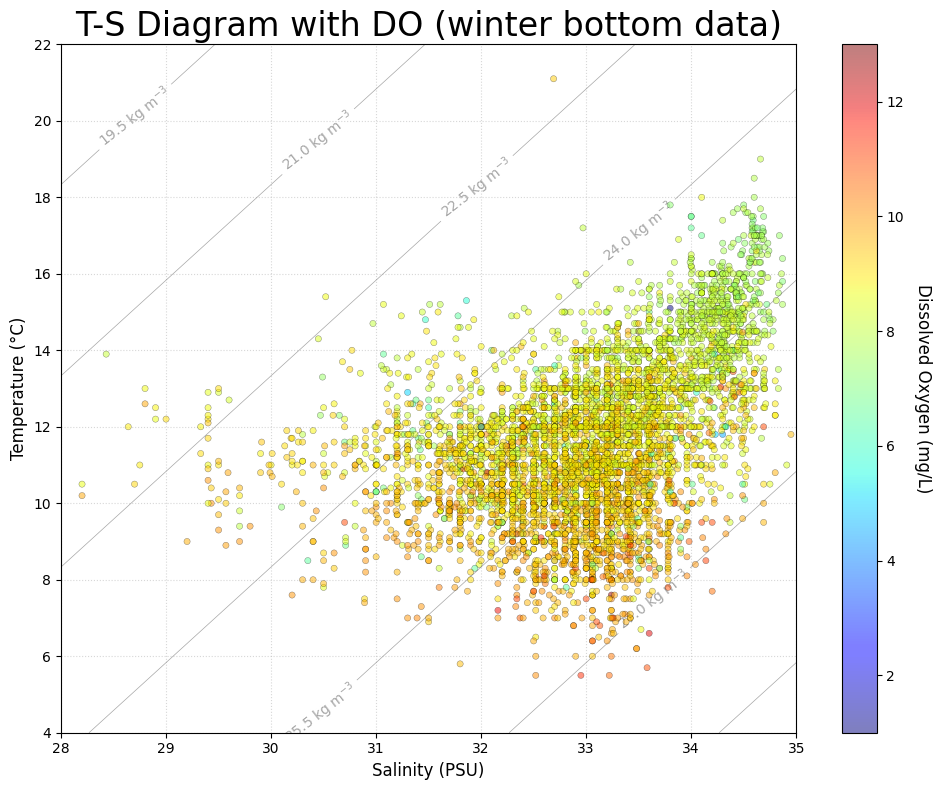

In [8]:
# Plot the winter bottom T-S diagram with DO

# --- STEP 1: Define the Density Calculation Function ---
# This linear approximation is standard for visualizing "Isopycnals" 
# within standard ranges (10-30°C, 25-35 PSU).
def calculate_density(T, S):
    return (0.75 * S) - (0.3 * T) + 4.0

# --- STEP 2: Prepare Data & Grid ---
# Safe numeric conversion (follow repo pattern: convert before aggregation)
S = pd.to_numeric(winter_bottom_df['salt'], errors='coerce').dropna()
T = pd.to_numeric(winter_bottom_df['wtemp'], errors='coerce').dropna()
DO = pd.to_numeric(winter_bottom_df['do_'], errors='coerce').dropna()

# Align indices after dropna (remove rows where any of S, T, DO is NaN)
valid_idx = S.index.intersection(T.index).intersection(DO.index)
S = S.loc[valid_idx]
T = T.loc[valid_idx]
DO = DO.loc[valid_idx]

if len(S) == 0:
    raise ValueError("No valid S, T, DO data after coercion. Check column names and data types.")

print(f"Valid rows for T-S plot: {len(S)}")
print(f"S range: {S.min():.2f} - {S.max():.2f} PSU")
print(f"T range: {T.min():.2f} - {T.max():.2f} °C")
print(f"DO range: {DO.min():.2f} - {DO.max():.2f} mg/L")

# Set manual limits for better visualization
s_min, s_max = 28.0, 35.0   
t_min, t_max = 4.0, 22.0   # lower range for denser cold water

# Create a background grid for the grey lines
s_grid = np.linspace(s_min, s_max, 100)
t_grid = np.linspace(t_min, t_max, 100)
S_grid, T_grid = np.meshgrid(s_grid, t_grid)
Sigma_grid = calculate_density(T_grid, S_grid)

# --- STEP 3: Create the Plot ---
plt.figure(figsize=(10, 8))

# A. Draw the Grey Isopycnals (Density Lines)
# We plot contours every 0.5 or 1.0 unit of density
contours = plt.contour(S_grid, T_grid, Sigma_grid, 
                       colors='grey', linestyles='-', linewidths=0.5, alpha=0.7)
plt.clabel(contours, inline=True, fontsize=10, fmt=r'%1.1f kg m$^{-3}$') # Labels the lines

# B. Draw the Scatter Points (Colored by DO)
sc = plt.scatter(S, T, c=DO, cmap='jet', s=20, edgecolors='k', linewidth=0.3, alpha=0.5, zorder=5)

# C. Add Colorbar & Labels
cbar = plt.colorbar(sc)
cbar.set_label('Dissolved Oxygen (mg/L)', rotation=270, labelpad=20, fontsize=12)

plt.xlabel('Salinity (PSU)', fontsize=12)
plt.ylabel('Temperature (°C)', fontsize=12)
plt.title('T-S Diagram with DO (winter bottom data)', fontsize=24)

# Apply the calculated limits
plt.xlim(s_min, s_max)
plt.ylim(t_min, t_max)
plt.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()